In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast
import cartopy.crs as ccrs
import geopandas
from cartopy.io import shapereader

from matplotlib.patches import Patch
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

CLIMATE_DATA_RES = 0.0083333

countries_polygons = geopandas.read_file(shapereader.natural_earth(resolution='10m', category='cultural', name='admin_0_countries'))

species_list = ['Abies_alba', 'Acer_campestre', 'Acer_pseudoplatanus', 'Alnus_glutinosa', 'Alnus_incana', 'Betula_pendula', 'Betula_pubescens', 'Carpinus_betulus', 'Corylus_avellana', 'Fagus_sylvatica', 'Fraxinus_excelsior', 'Picea_abies', 'Pinus_halepensis', 'Pinus_nigra', 'Pinus_pinaster', 'Pinus_sylvestris', 'Populus_tremula', 'Prunus_avium', 'Quercus_ilex', 'Quercus_petraea', 'Quercus_pubescens', 'Quercus_robur', 'Quercus_suber', 'Sorbus_aucuparia']

# bands start at 1, not 0!
band_names = {1: 'historical', 2: 'present', 5: 'ssp1', 6: 'ssp1a', 9: 'ssp2', 10: 'ssp2a', 13: 'ssp5', 14: 'ssp5a'}
future_scenarios = list(band_names.values())[2:]

import amoc_plots
import amoc_computations as amoc_comp
import importlib

ERROR 1: PROJ: proj_create_from_database: Open of /home/konni/anaconda3/envs/amoc/share/proj failed


# Read Optimized Data and Occurrences

In [4]:
OPTIMIZED_DATA = "data/optimized_dataset_every_100.csv.gz"
OCCURRENCES = 'data/heubel_occurrences.csv'

In [5]:
rows = []
SKIP = 1 # set higher to just read every nth data point, for testing purposes
for chunk in pd.read_csv(OPTIMIZED_DATA, sep=';', chunksize=1000):
    rows.append(chunk.iloc[::SKIP])
df_final_optimized = pd.concat(rows, ignore_index=True)
df_final_optimized['opt_portfolio'] = df_final_optimized['opt_portfolio'].apply(ast.literal_eval)

In [6]:
df_final_optimized.head()

,y,x,Abies_alba-historical,Abies_alba-present,Abies_alba-ssp1,Abies_alba-ssp2,Abies_alba-ssp5,Abies_alba-ssp1a,Abies_alba-ssp2a,Abies_alba-ssp5a,...,opt_portfolio_max_prob,opt_single_species_prob_present,opt_single_species_prob_ssp1,opt_single_species_prob_ssp1a,opt_single_species_prob_ssp2,opt_single_species_prob_ssp2a,opt_single_species_prob_ssp5,opt_single_species_prob_ssp5a,opt_single_species_avg_prob,opt_single_species_max_prob
0,71.104027,25.554027,1.0,2.0,2.0,1.0,8.0,0.0,1.0,12.0,...,33.868065,13.0,8.0,40.0,5.0,55.0,3.0,56.0,25.714286,56.0
1,71.087360,25.570694,0.0,3.0,6.0,3.0,10.0,0.0,1.0,17.0,...,40.075416,14.0,9.0,46.0,6.0,62.0,3.0,68.0,29.714286,68.0
2,71.070694,25.320694,2.0,2.0,1.0,0.0,5.0,0.0,1.0,11.0,...,28.409485,12.0,6.0,35.0,4.0,45.0,2.0,40.0,20.571429,45.0
3,71.062360,25.520694,0.0,1.0,4.0,4.0,8.0,0.0,0.0,6.0,...,27.446910,7.0,7.0,16.0,4.0,27.0,2.0,39.0,14.571429,39.0
4,71.054027,25.579027,0.0,1.0,5.0,6.0,10.0,0.0,0.0,6.0,...,32.399324,8.0,8.0,17.0,5.0,31.0,3.0,46.0,16.857143,46.0


In [22]:
assert np.all(df_final_optimized['opt_portfolio_min_prob'] + 0.000000001 >= df_final_optimized['opt_single_species_min_prob']) , "Error! Portfolio has worse suitability than single species!"

In [8]:
heubel = pd.read_csv(OCCURRENCES, sep=',').rename(columns={'LON': 'lon', 'LAT': 'lat'})

heubel['SPECIES_NAME_NORM'] = heubel['species'].str.replace(' ', '_')
heubel_amoc_species = heubel[heubel['SPECIES_NAME_NORM'].isin(species_list)].copy()
heubel_amoc_species = heubel_amoc_species[heubel_amoc_species['lat'] > 36] # cut out canary islands etc

column_name = heubel_amoc_species['SPECIES_NAME_NORM'] + '-present'
occurrence_24_species_dataset = heubel_amoc_species.copy()

# Align optimized data with occurrence dataset

In [9]:
# for each occurrence, we want to find the closest suitability row, and get the corresponding suitability of the mauri species.
from scipy.spatial import cKDTree
suitability = df_final_optimized.copy().reset_index()
suitability_coords = suitability[['x', 'y']].values
# kdtree of the suitability coordinates, to find the closest to a mauri coordinate
tree = cKDTree(suitability_coords)
# for each occurrence coordinate, find the closest suitability entry
heubel_coords = occurrence_24_species_dataset[['lon', 'lat']].values
distances, indices = tree.query(heubel_coords, k=1)

In [10]:
ordered_subset = suitability.iloc[indices]
occurrence_24_species_dataset['amoc_coords'] = indices
occurrence_24_species_dataset['amoc_distance'] = distances
occurrence_24_species_dataset['amoc_lon'] = suitability.iloc[indices]['x'].values
occurrence_24_species_dataset['amoc_lat'] = suitability.iloc[indices]['y'].values


for scenario in future_scenarios + ['historical', 'present']:
    colname_per_row = occurrence_24_species_dataset['SPECIES_NAME_NORM'] + "-" + scenario
    occurrence_24_species_dataset['occurring_species_suitability_' + scenario] = [ordered_subset.iloc[i][colname_per_row.iloc[i]] for i in range(len(ordered_subset))]

occurrence_24_species_dataset['future_min_suitability'] = occurrence_24_species_dataset[['occurring_species_suitability_' + scenario for scenario in future_scenarios]].min(axis=1)
occurrence_24_species_dataset['future_min_suitability_amoc_on'] = occurrence_24_species_dataset[['occurring_species_suitability_' + scenario for scenario in future_scenarios if not scenario.endswith('a')]].min(axis=1)
occurrence_24_species_dataset['future_mean_suitability'] = occurrence_24_species_dataset[['occurring_species_suitability_' + scenario for scenario in future_scenarios]].mean(axis=1)
# takes 5m

# get the species with highest present suitability for a pixel (there could be multiple trees on one pixel)
deduped_occurrence_24_species_dataset = occurrence_24_species_dataset.loc[
    occurrence_24_species_dataset.groupby(['lon', 'lat'])['occurring_species_suitability_present'].idxmax()
].reset_index(drop=True)

In [11]:
filtered_df = df_final_optimized.merge(
    deduped_occurrence_24_species_dataset,
    left_on=['x', 'y'],
    right_on=['amoc_lon', 'amoc_lat'],
    how='inner'
)

## Plots

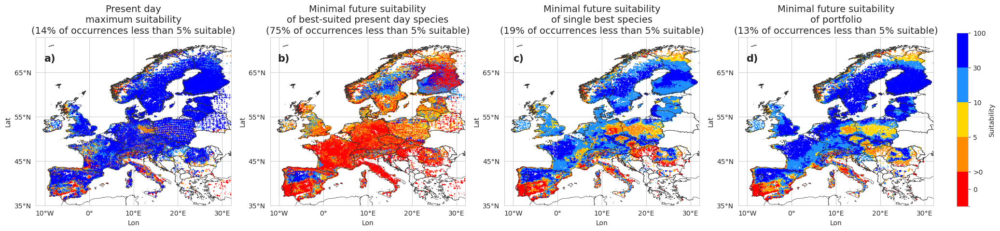

In [29]:
importlib.reload(amoc_plots)
amoc_plots.plot_present_historical_single_portfolio(occurrence_24_species_dataset, deduped_occurrence_24_species_dataset, filtered_df, filename=None)

## Suitabilities across scenarios

/tmp/ipykernel_60335/4140227836.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, 6, figsize=(40, 6))


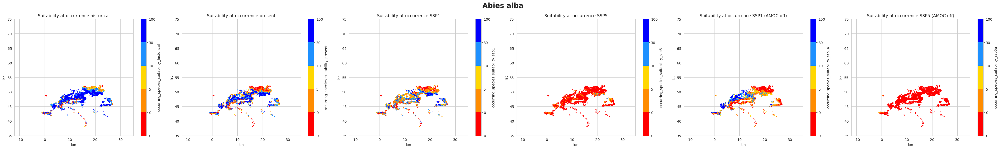

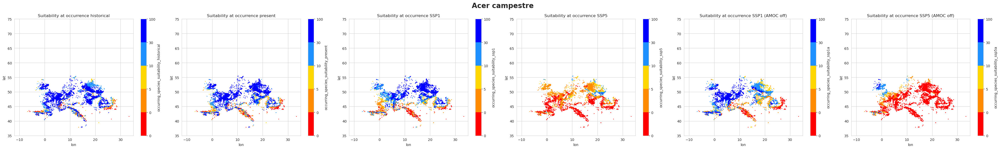

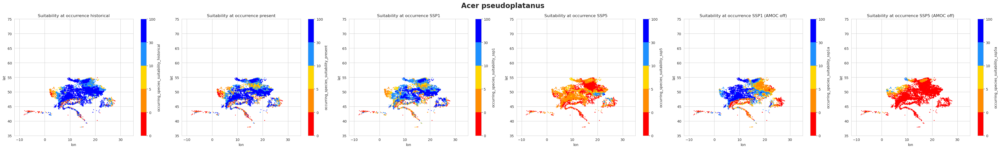

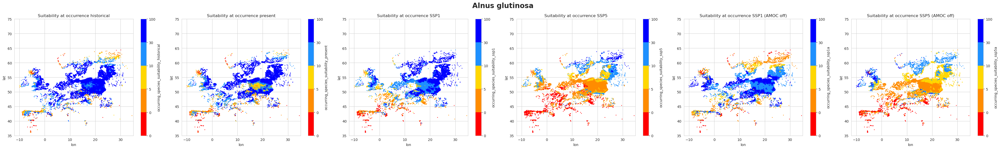

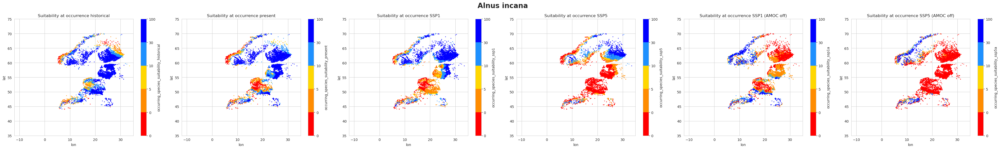

...

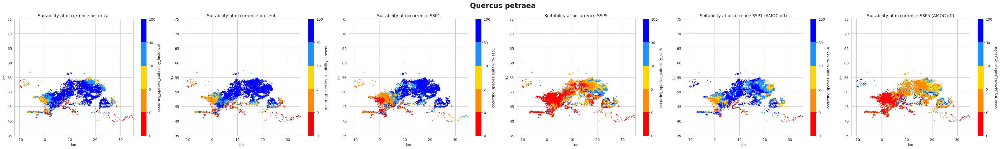

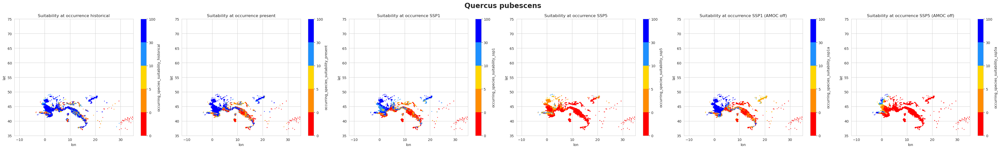

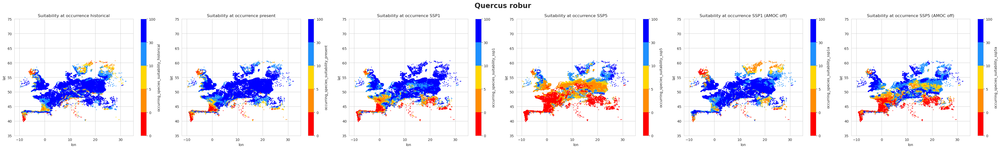

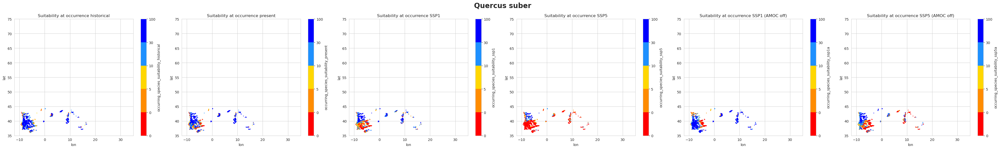

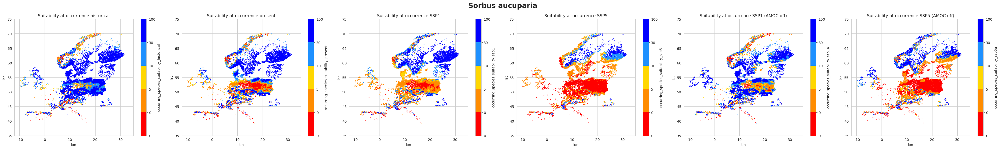

In [13]:
importlib.reload(amoc_plots)
number_of_false_negatives = []
number_of_total_observations = []

for species in species_list:
    fig, ax = plt.subplots(1, 6, figsize=(40, 6))
    species_occurrences = occurrence_24_species_dataset[occurrence_24_species_dataset['SPECIES_NAME_NORM'] == species]

    all_pixels = len(species_occurrences)

    species_occurrences_with_suitabilities = occurrence_24_species_dataset[occurrence_24_species_dataset['SPECIES_NAME_NORM'] == species].copy()
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_historical', ax=ax[0], s=1, title='Suitability at occurrence historical', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_present', ax=ax[1], s=1, title='Suitability at occurrence present', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp1', ax=ax[2], s=1, title='Suitability at occurrence SSP1', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp5', ax=ax[3], s=1, title='Suitability at occurrence SSP5', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp1a', ax=ax[4], s=1, title='Suitability at occurrence SSP1 (AMOC off)', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp5a', ax=ax[5], s=1, title='Suitability at occurrence SSP5 (AMOC off)', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)

    for axx in ax:
        axx.set_xlim([-12, 35])
        axx.set_ylim([35, 75])

    fig.suptitle(species.replace('_', ' '), fontsize=20, fontweight='bold')
    fig.tight_layout()

# Extrapolated to continent

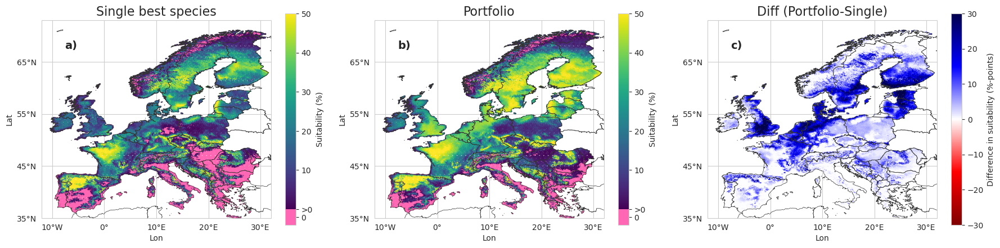

In [31]:
amoc_plots.plot_single_vs_portfolio(df_final_optimized, titleaddition='ensemble mean, all scenarios', filename=None)

## Suitability numbers

In [15]:
ZERO_THRESHOLD = 0.01
LOW_THRESHOLD = 5

In [16]:
# Area of each pixel (km²) depends on latitude; CLIMATE_DATA_RES is the pixel size in degrees
df_final_optimized['area_km2'] = df_final_optimized['y'].map(
    lambda lat: amoc_comp.get_area_for_lon_and_lat_with_formulas_specific_gc_size(lat, CLIMATE_DATA_RES, CLIMATE_DATA_RES)
) / 1e6

total_area = df_final_optimized['area_km2'].sum()
print(f'Total area: {total_area:,.0f} km²')

improved_area = df_final_optimized.loc[df_final_optimized['opt_portfolio_min_prob'] > df_final_optimized['opt_single_species_min_prob'], 'area_km2'].sum()
print(f'Area improved by portfolio over single-species: {improved_area:,.0f} km² ({improved_area / total_area:.1%} of total area)')

for label, col in [('best species', 'opt_single_species_min_prob'), ('portfolio', 'opt_portfolio_min_prob')]:
    zero_area = df_final_optimized.loc[df_final_optimized[col] < ZERO_THRESHOLD, 'area_km2'].sum()
    low_area = df_final_optimized.loc[df_final_optimized[col] < LOW_THRESHOLD, 'area_km2'].sum()
    print(f'Area of future marginal suitability (<{LOW_THRESHOLD}%) for {label}: {low_area:,.0f} km² ({low_area / total_area:.1%} of total area)')
    print(f'Area of future zero suitability (<{ZERO_THRESHOLD}%) for {label}: {zero_area:,.0f} km² ({zero_area / total_area:.1%} of total area)')


Total area: 50,052 km²
Area improved by portfolio over single-species: 31,796 km² (63.5% of total area)
Area of future marginal suitability (<5%) for best species: 16,337 km² (32.6% of total area)
Area of future zero suitability (<0.01%) for best species: 9,248 km² (18.5% of total area)
Area of future marginal suitability (<5%) for portfolio: 12,712 km² (25.4% of total area)
Area of future zero suitability (<0.01%) for portfolio: 5,654 km² (11.3% of total area)


In [17]:
improved_pixels = df_final_optimized[df_final_optimized['opt_portfolio_min_prob'] > df_final_optimized['opt_single_species_min_prob']]
average_worstcase_portfolio = np.sum(improved_pixels['opt_portfolio_min_prob'].mul(improved_pixels['area_km2']))/np.sum(improved_pixels['area_km2'])
average_worstcase_single = np.sum(improved_pixels['opt_single_species_min_prob'].mul(improved_pixels['area_km2']))/np.sum(improved_pixels['area_km2'])
print(f'Average worst-case improvement from {average_worstcase_single:,.1f} to {average_worstcase_portfolio:,.1f}')

Average worst-case improvement from 16.9 to 26.1


In [18]:
LOW_THRESHOLD = 5

print('Share of future marginal suitability for best species:', len(df_final_optimized[df_final_optimized['opt_single_species_min_prob'] < LOW_THRESHOLD]) / len(df_final_optimized))
print('Share of future marginal suitability for portfolio:', len(df_final_optimized[df_final_optimized['opt_portfolio_min_prob'] < LOW_THRESHOLD]) / len(df_final_optimized))

print('Share of future zero suitability for best species:', len(df_final_optimized[df_final_optimized['opt_single_species_min_prob'] < 0.1]) / len(df_final_optimized))
print('Share of future zero suitability for portfolio:', len(df_final_optimized[df_final_optimized['opt_portfolio_min_prob'] < 0.1]) / len(df_final_optimized))

Share of future marginal suitability for best species: 0.3016868019147481
Share of future marginal suitability for portfolio: 0.23385208363553475
Share of future zero suitability for best species: 0.1585158629836086
Share of future zero suitability for portfolio: 0.09657666245311561


# Proposed species

In [19]:
df_final_optimized_at_least_two = df_final_optimized[df_final_optimized['opt_portfolio'].map(len) > 1].copy()

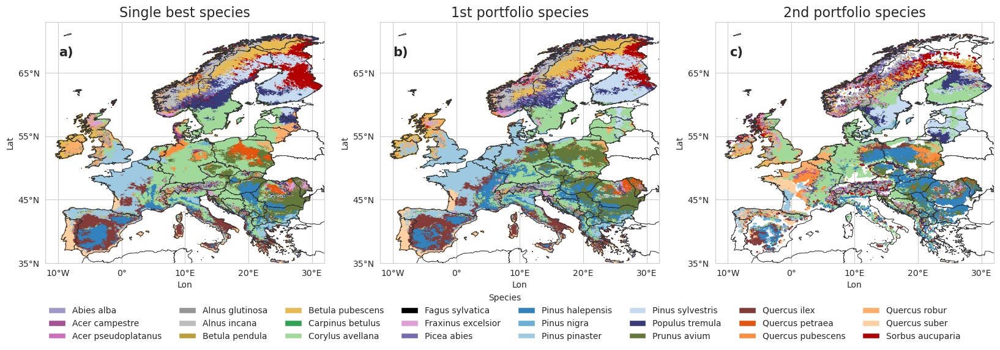

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})

df_final_optimized['top'] = df_final_optimized['opt_portfolio'].map(lambda pf: int(sorted(pf.items(), key=lambda item: item[1], reverse=True)[0][0]))
df_final_optimized_at_least_two['second'] = df_final_optimized_at_least_two['opt_portfolio'].map(lambda pf: int(sorted(pf.items(), key=lambda item: item[1], reverse=True)[1][0]))

amoc_plots.plot_single_best_species(ax[0], df_final_optimized, species_list, colorbar=False)
amoc_plots.plot_single_best_species(ax[1], df_final_optimized, species_list, column='top', colorbar=False)
amoc_plots.plot_single_best_species(ax[2], df_final_optimized_at_least_two, species_list, column='second', colorbar=False)

legend_elements = [
    Patch(facecolor=amoc_plots.species_to_color[species], label=species.replace('_', ' '))
    for species in species_list
]

fig.legend(
    handles=legend_elements,
    title="Species",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),  # center below the subplots
    ncol=len(species_list)/3,
    frameon=False
)

fig.subplots_adjust(bottom=-0.28)

ax[0].set_title('Single best species', fontsize=16)
ax[1].set_title('1st portfolio species', fontsize=16)
ax[2].set_title('2nd portfolio species', fontsize=16)

for idx, letter in enumerate(['a', 'b', 'c']):
    ax[idx].text(0.1, 0.9, letter + ')', fontsize=15, weight='bold',
                 va='top', ha='right', transform=ax[idx].transAxes)
    ax[idx].add_geometries(
        countries_polygons['geometry'], crs=ccrs.PlateCarree(),
        facecolor='none', edgecolor='0.2', linewidth=0.5
    )
    ax[idx].set_extent(amoc_plots.europe_extent, crs=ccrs.PlateCarree())
    ax[idx].set_ylabel('Lat')
    ax[idx].set_xlabel('Lon')
    ax[idx].set_xticks([-10, 0, 10, 20, 30], crs=ccrs.PlateCarree())
    ax[idx].set_yticks([35, 45, 55, 65], crs=ccrs.PlateCarree())
    ax[idx].xaxis.set_major_formatter(LONGITUDE_FORMATTER)
    ax[idx].yaxis.set_major_formatter(LATITUDE_FORMATTER)

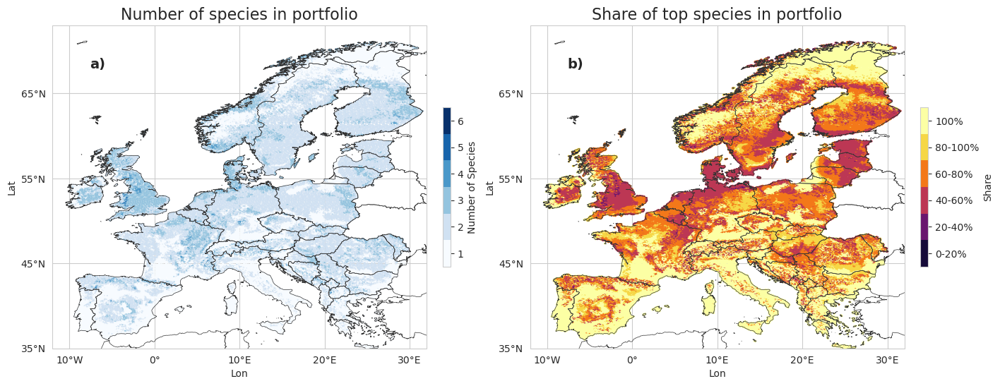

In [21]:
importlib.reload(amoc_plots)
amoc_plots.plot_n_species_of_portfolio(df_final_optimized, filename=None)